Rows: 55 Columns: 16
-- Column specification --------------------------------------------------------
Delimiter: "\t"
chr  (2): sample_id, condition
dbl (14): size, richness, d1, shannon, d2, simpson, d3, d4, chao1, ace, gini...

i Use `spec()` to retrieve the full column specification for this data.
i Specify the column types or set `show_col_types = FALSE` to quiet this message.
Warning message:
"There was 1 warning in `mutate()`.
i In argument: `across(everything(), as.numeric)`.
Caused by warning:
! NAs introduced by coercion"


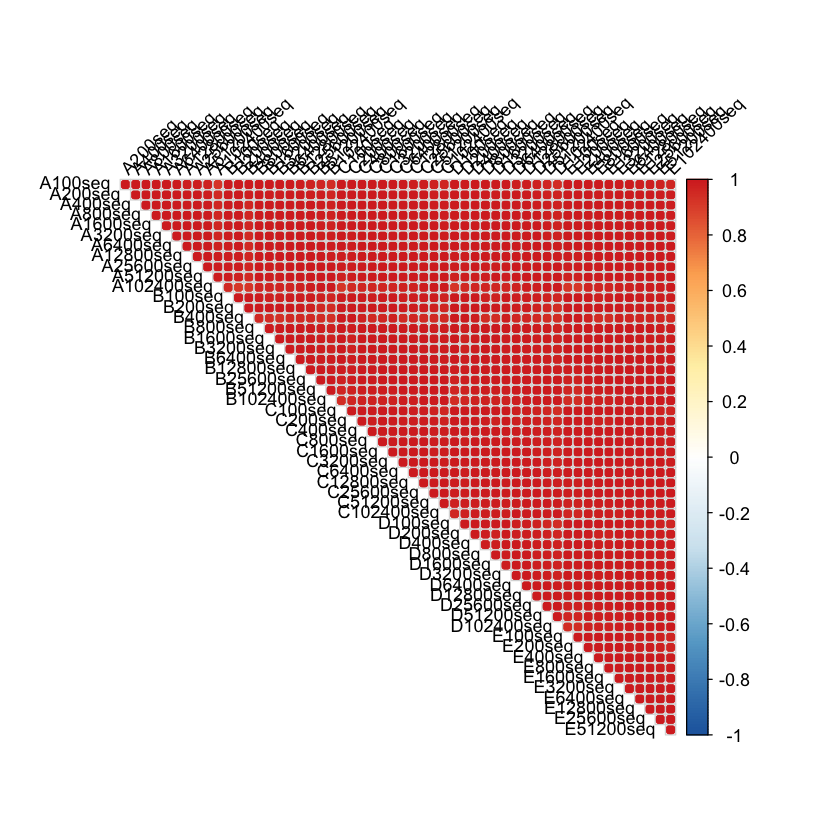

In [10]:

# CORRELOGRAMA DE PEARSON ENTRE MÉTRICAS DE DIVERSIDAD

library(tidyverse)
library(corrplot)

# 1. Leer matriz de diversidad
df <- read_tsv(
  "../results/diversity_matrix/diversity_matrix_A.tsv"
)

# 2. Convertir a matriz numérica
# Primera columna = métricas
mat <- df %>%
  column_to_rownames(var = names(df)[1]) %>%
  mutate(across(everything(), as.numeric)) %>%
  as.matrix()

# 3. Transponer para que las filas sean
# observaciones y las columnas sean métricas
mat_t <- t(mat)

# 4. Calcular correlación de Pearson
cor_pearson <- cor(
  mat_t,
  method = "pearson",
  use = "pairwise.complete.obs"
)

# 5. Graficar correlograma de círculos

corrplot(
  cor_pearson,
  method = "circle",
  type = "upper",
  order = "original",
  diag = FALSE,
  col.lim = c(-1, 1),
  col = colorRampPalette(
    c("#2166AC", "#67A9CF", "#D1E5F0",
      "white",
      "#FFF0B3", "#FDAE61", "#D73027")
  )(200),
  tl.col = "black",
  tl.srt = 45,
  tl.cex = 0.9,
  cl.cex = 0.9,
  addgrid.col = "grey85"
)

# 6. Guardar matriz de correlaciones
write.csv(
  cor_pearson,
  "../results/correlacion_pearson.csv"
)


In [11]:
round(quantile(vals, probs = c(0, 0.25, 0.5, 0.75, 1), na.rm = TRUE), 3)

0%   25%   50%   75%  100% 
0.919 0.986 0.993 0.998 1.000


Escenarios disponibles:
[1] "A" "B" "C" "D" "E"

Profundidades disponibles:
 [1]    100    200    400    800   1600   3200   6400  12800  25600  51200
[11] 102400

----------------------------------------
Escenario: A - Control
Numero de observaciones: 11
Profundidades: 100, 200, 400, 800, 1600, 3200, 6400, 12800, 25600, 51200, 102400
----------------------------------------

Escenario A - Control : correlograma mostrado y guardado.

----------------------------------------
Escenario: B - Na<U+00EF>ve
Numero de observaciones: 11
Profundidades: 100, 200, 400, 800, 1600, 3200, 6400, 12800, 25600, 51200, 102400
----------------------------------------


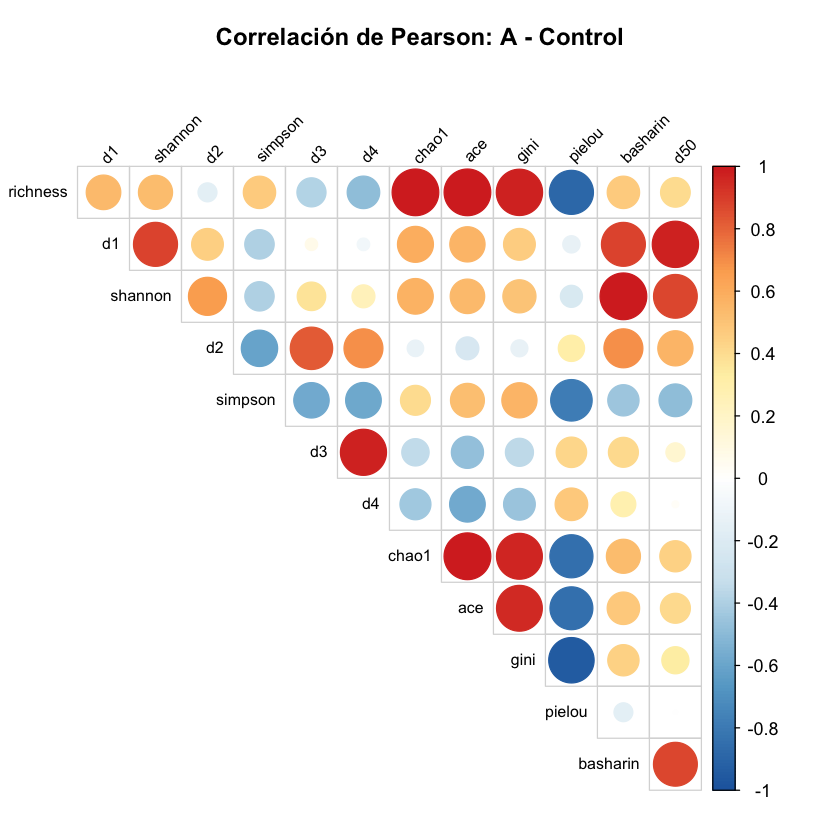


Escenario B - Na<U+00EF>ve : correlograma mostrado y guardado.

----------------------------------------
Escenario: C - Sangre perif<U+00E9>rica
Numero de observaciones: 11
Profundidades: 100, 200, 400, 800, 1600, 3200, 6400, 12800, 25600, 51200, 102400
----------------------------------------


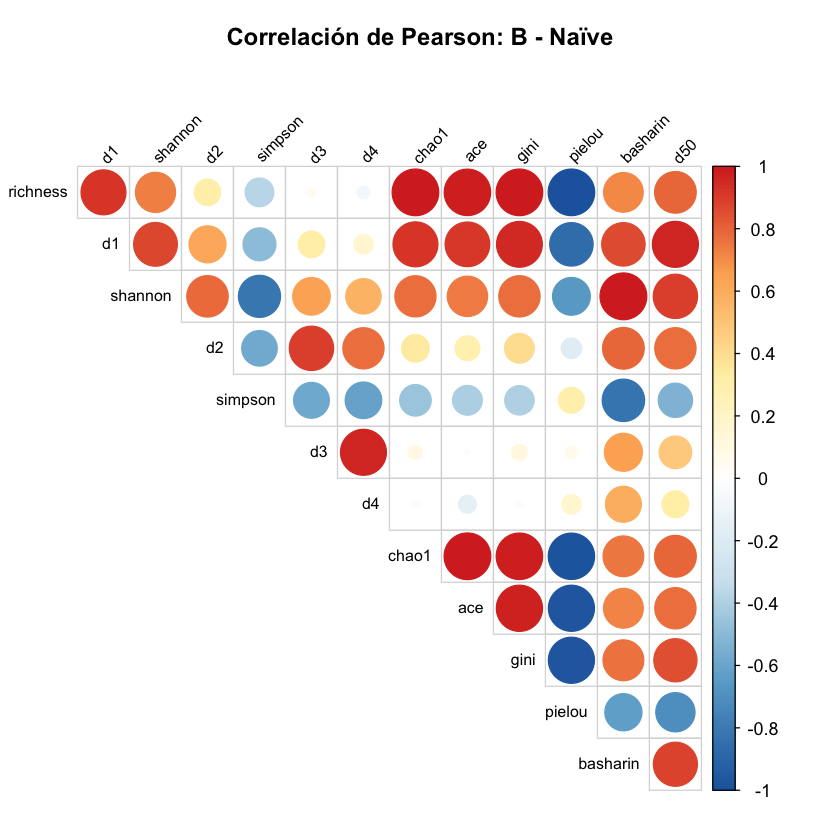


Escenario C - Sangre perif<U+00E9>rica : correlograma mostrado y guardado.

----------------------------------------
Escenario: D - Folicular
Numero de observaciones: 11
Profundidades: 100, 200, 400, 800, 1600, 3200, 6400, 12800, 25600, 51200, 102400
----------------------------------------


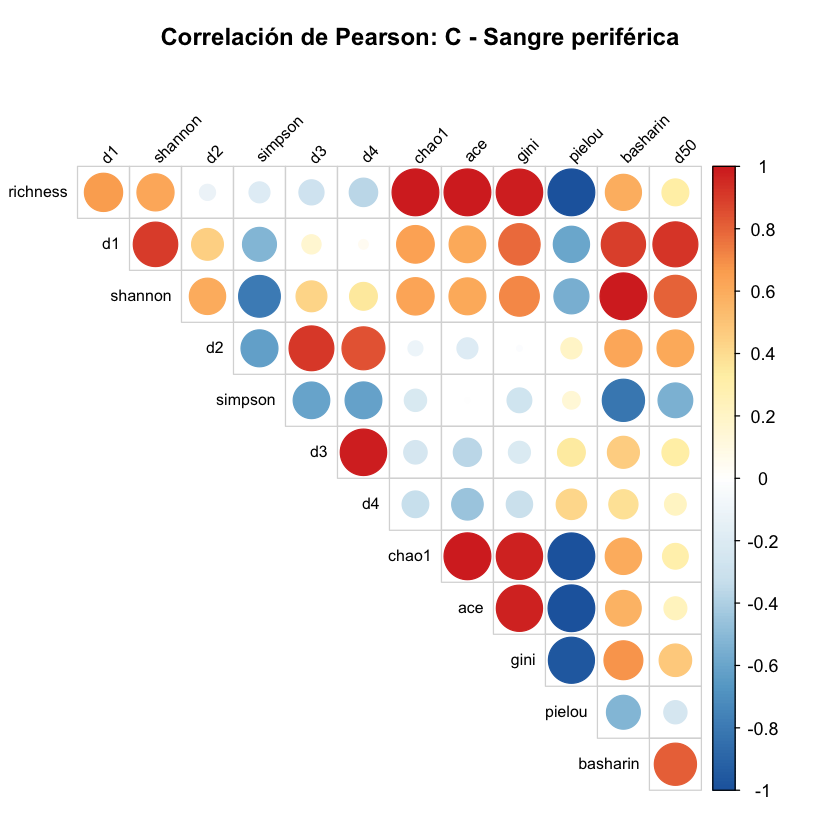


Escenario D - Folicular : correlograma mostrado y guardado.

----------------------------------------
Escenario: E - Extrafolicular
Numero de observaciones: 11
Profundidades: 100, 200, 400, 800, 1600, 3200, 6400, 12800, 25600, 51200, 102400
----------------------------------------


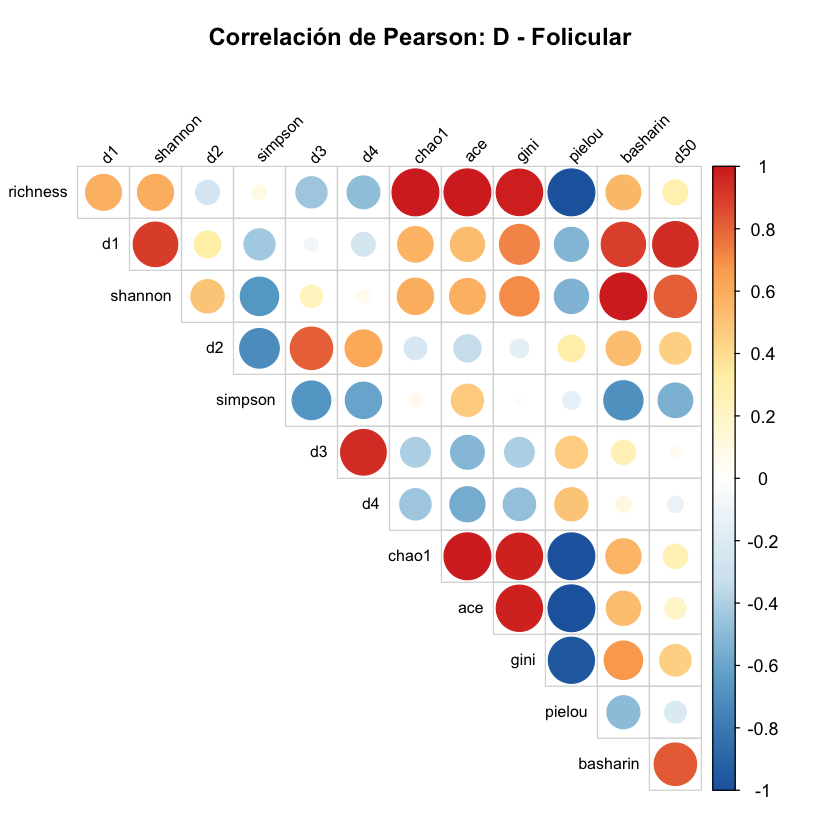


Escenario E - Extrafolicular : correlograma mostrado y guardado.

Analisis finalizado.
 Resultados guardados en:
 /Users/catg/Desktop/SOFIAC/Gitsofia/tesisbioinf-sofia/results/correlation 


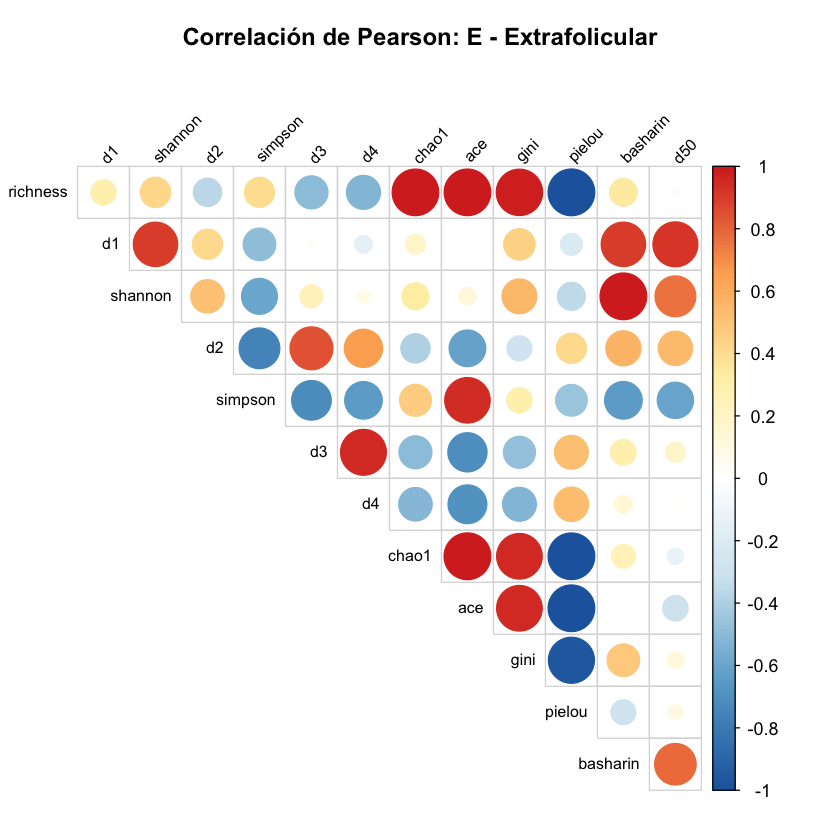

In [8]:

# ============================================================
# CORRELOGRAMAS DE PEARSON ENTRE METRICAS DE DIVERSIDAD
# Cinco escenarios: A, B, C, D y E
# Se utilizan todas las profundidades de cada escenario
# Los graficos se muestran en RStudio y se guardan en disco
# ============================================================

library(tidyverse)
library(corrplot)

# 1. Leer matriz completa
df <- read_tsv(
  "../results/diversity_matrix/diversity_matrix_A.tsv",
  show_col_types = FALSE
)

# 2. Definir metricas de diversidad
metricas <- c(
  "richness", "d1", "shannon", "d2", "simpson",
  "d3", "d4", "chao1", "ace", "gini",
  "pielou", "basharin", "d50"
)

# 3. Definir nombres de escenarios
nombres <- c(
  A = "Control",
  B = "Na\u00EFve",
  C = "Sangre perif\u00E9rica",
  D = "Folicular",
  E = "Extrafolicular"
)

# 4. Definir carpeta de salida
outdir <- "/Users/catg/Desktop/SOFIAC/Gitsofia/tesisbioinf-sofia/results/correlation"

dir.create(
  outdir,
  recursive = TRUE,
  showWarnings = FALSE
)

# 5. Comprobar estructura de los datos
cat("\nEscenarios disponibles:\n")
print(unique(df$condition))

cat("\nProfundidades disponibles:\n")
print(sort(unique(df$size)))

# Verificar que existan las columnas necesarias
columnas_faltantes <- setdiff(
  c("condition", "size", metricas),
  names(df)
)

if (length(columnas_faltantes) > 0) {
  stop(
    "Faltan estas columnas en la matriz: ",
    paste(columnas_faltantes, collapse = ", ")
  )
}

# 6. Definir funcion para generar el correlograma
generar_correlograma <- function(cor_pearson, esc, nombre, outdir) {

  titulo <- paste(
    "Correlaci\u00F3n de Pearson:",
    esc, "-", nombre
  )

  # Guardar matriz de correlaciones
  write.csv(
    cor_pearson,
    file.path(
      outdir,
      paste0("correlacion_Pearson_", esc, ".csv")
    ),
    row.names = TRUE
  )

  # Funcion de dibujo reutilizada para pantalla y archivo
  dibujar <- function() {
    corrplot(
      cor_pearson,
      method = "circle",
      type = "upper",
      order = "original",
      diag = FALSE,
      col.lim = c(-1, 1),
      col = colorRampPalette(
        c(
          "#2166AC", "#67A9CF", "#D1E5F0",
          "white",
          "#FFF0B3", "#FDAE61", "#D73027"
        )
      )(200),
      tl.col = "black",
      tl.srt = 45,
      tl.cex = 0.8,
      cl.cex = 0.9,
      addgrid.col = "grey85",
      title = titulo,
      mar = c(0, 0, 3, 0)
    )
  }

  # Mostrar el correlograma en RStudio
  dibujar()

  # Guardar el mismo correlograma como PNG
  png(
    filename = file.path(
      outdir,
      paste0("correlograma_", esc, ".png")
    ),
    width = 1800,
    height = 1500,
    res = 180
  )

  dibujar()
  dev.off()

  cat(
    "\nEscenario", esc, "-", nombre,
    ": correlograma mostrado y guardado.\n"
  )
}

# 7. Generar los cinco correlogramas
escenarios <- c("A", "B", "C", "D", "E")

for (esc in escenarios) {

  # Seleccionar el escenario y ordenar por profundidad
  datos_esc <- df %>%
    filter(condition == esc) %>%
    arrange(size)

  if (nrow(datos_esc) < 2) {
    warning(
      paste(
        "El escenario", esc,
        "tiene menos de dos observaciones o no esta presente."
      )
    )
    next
  }

  cat(
    "\n----------------------------------------\n",
    "Escenario: ", esc, " - ", nombres[[esc]], "\n",
    "Numero de observaciones: ", nrow(datos_esc), "\n",
    "Profundidades: ",
    paste(sort(unique(datos_esc$size)), collapse = ", "),
    "\n----------------------------------------\n",
    sep = ""
  )

  # Seleccionar solo las metricas
  mat <- datos_esc %>%
    select(all_of(metricas)) %>%
    mutate(across(everything(), as.numeric))

  # Excluir metricas sin variacion o con datos insuficientes
  validas <- map_lgl(mat, function(x) {
    sum(!is.na(x)) >= 2 &&
      is.finite(sd(x, na.rm = TRUE)) &&
      sd(x, na.rm = TRUE) > 0
  })

  mat <- mat[, validas, drop = FALSE]

  if (ncol(mat) < 2) {
    warning(
      paste("No hay suficientes metricas validas para", esc)
    )
    next
  }

  # Calcular correlacion de Pearson entre metricas
  cor_pearson <- cor(
    mat,
    method = "pearson",
    use = "pairwise.complete.obs"
  )

  # Mostrar y guardar el correlograma
  generar_correlograma(
    cor_pearson = cor_pearson,
    esc = esc,
    nombre = nombres[[esc]],
    outdir = outdir
  )
}

cat(
  "\nAnalisis finalizado.\n",
  "Resultados guardados en:\n",
  outdir,
  "\n"
)
